# 🌍 Global Youth Tobacco Susceptibility — End-to-End ML Pipeline

**Target**: `Susceptibility` → binary classification (`susceptible` vs `non-susceptible`)  
**Data**: Global WHO-region dataset · All features retained (no selection)  
**Class balance**: Class-weight correction applied  
**Publication target**: *The Lancet* — Lancet-standard reporting and visualisations

### Sections
1. Environment & Reproducibility  
2. Data Ingestion & EDA  
3. Feature Engineering & Preprocessing  
4. Model Training & HPO (RandomizedSearchCV)  
5. Evaluation — Accuracy · Precision · Recall · F1 · AUC  
6. Lancet-Ready Figures & Tables  
7. Final Summary

## 1 · Environment & Reproducibility

In [1]:
import warnings, time
warnings.filterwarnings("ignore")

import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, randint

from sklearn.model_selection  import (train_test_split, StratifiedKFold,
                                       cross_validate, RandomizedSearchCV,
                                       learning_curve)
from sklearn.pipeline          import Pipeline
from sklearn.preprocessing     import OrdinalEncoder, LabelEncoder, RobustScaler
from sklearn.impute            import SimpleImputer
from sklearn.compose           import ColumnTransformer
from sklearn.base              import BaseEstimator, TransformerMixin

from sklearn.linear_model  import LogisticRegression
from sklearn.ensemble      import (RandomForestClassifier,
                                   GradientBoostingClassifier,
                                   ExtraTreesClassifier)
from sklearn.svm           import SVC
from sklearn.neighbors     import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay,
    ConfusionMatrixDisplay, average_precision_score,
    balanced_accuracy_score, roc_curve, precision_recall_curve
)
from sklearn.inspection  import permutation_importance
from sklearn.calibration import calibration_curve

# ── Global config ──────────────────────────────────────────────────────────────
SEED       = 42
TEST_SIZE  = 0.20
CV_FOLDS   = 5
N_ITER_HPO = 40

# ── UPDATE THIS PATH to your full global dataset ───────────────────────────────
DATA_PATH  = "D:\RESEARCH\Youth Tobacco Survey\data preparation\susceptibility.csv"   # <── CHANGE THIS

# ── Lancet-style plot theme ────────────────────────────────────────────────────
LANCET_COLORS = ["#00468B", "#ED0000", "#42B540", "#0099B4",
                 "#925E9F", "#FDAF91", "#AD002A", "#ADB6B6"]

plt.rcParams.update({
    "figure.dpi"        : 300,
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
    "font.family"       : "sans-serif",
    "font.size"         : 11,
    "axes.titlesize"    : 12,
    "axes.labelsize"    : 11,
    "legend.fontsize"   : 9,
    "xtick.labelsize"   : 9,
    "ytick.labelsize"   : 9,
})

np.random.seed(SEED)
print("✅  Environment ready")

✅  Environment ready


## 2 · Data Ingestion & EDA

In [2]:
# ── 2.1  Load ──────────────────────────────────────────────────────────────────
df = pd.read_csv(DATA_PATH)

# Drop near-constant / non-informative column (same as original pipeline)
if "q10" in df.columns:
    df.drop(columns=["q10"], inplace=True)

TARGET = "Susceptibility"
print(f"Shape      : {df.shape}")
print(f"Columns    : {list(df.columns)}")
print(f"\nTarget distribution:")
print(df[TARGET].value_counts())
print(f"\nWHO Regions in dataset:")
if "WHO_Region" in df.columns:
    print(df["WHO_Region"].value_counts())
elif "Region" in df.columns:
    print(df["Region"].value_counts())
df.head(3)

Shape      : (795393, 30)
Columns    : ['q1', 'q2', 'q3', 'q4', 'q5', 'q6', 'q9', 'q11', 'q12', 'q13', 'q14', 'q15', 'q16', 'q17', 'q18', 'q19', 'q20', 'q21', 'q22', 'q23', 'FinalWgt', 'PSU', 'Stratum', 'Country', 'Year', 'Region', 'Income Group', 'Country_Year', 'Susceptibility', 'q27']

Target distribution:
Susceptibility
non-susceptible    533020
susceptible        262373
Name: count, dtype: int64

WHO Regions in dataset:
Region
Europe                   357422
America                  121809
Western Pacific          112418
African                  103629
Eastern Mediterranean     64654
South East Asia           35461
Name: count, dtype: int64


,q1,q2,q3,q4,q5,q6,q9,q11,q12,q13,...,FinalWgt,PSU,Stratum,Country,Year,Region,Income Group,Country_Year,Susceptibility,q27
0,NaN,2.0,4.0,2.0,2.0,2.0,13 or below,No,No,Yes,...,187.987393,1,201301001,Algeria,2013,African,Upper middle income,Algeria_2013,non-susceptible,no
1,1.0,2.0,4.0,2.0,2.0,2.0,14 years,No,Yes,Yes,...,187.987393,1,201301001,Algeria,2013,African,Upper middle income,Algeria_2013,non-susceptible,no
2,1.0,2.0,4.0,2.0,2.0,2.0,14 years,No,Yes,Yes,...,187.987393,1,201301001,Algeria,2013,African,Upper middle income,Algeria_2013,non-susceptible,no


              missing  missing_%    dtype  n_unique
q3             151943       19.1  float64         4
q6             145604       18.3  float64         2
q16             63856        8.0   object         2
q2              54023        6.8  float64         2
q5              46398        5.8  float64         2
q1              45252        5.7  float64         7
q4              33223        4.2  float64         2
q18             20242        2.5   object         2
q20             18944        2.4   object         2
q17             18203        2.3   object         2
q14             17692        2.2   object         2
q22             14299        1.8   object         2
q23             13371        1.7   object         2
q21             12763        1.6   object         2
q19             12615        1.6   object         2
q15             10685        1.3   object         2
q13              8437        1.1   object         2
q11              7583        1.0   object         2
q12         

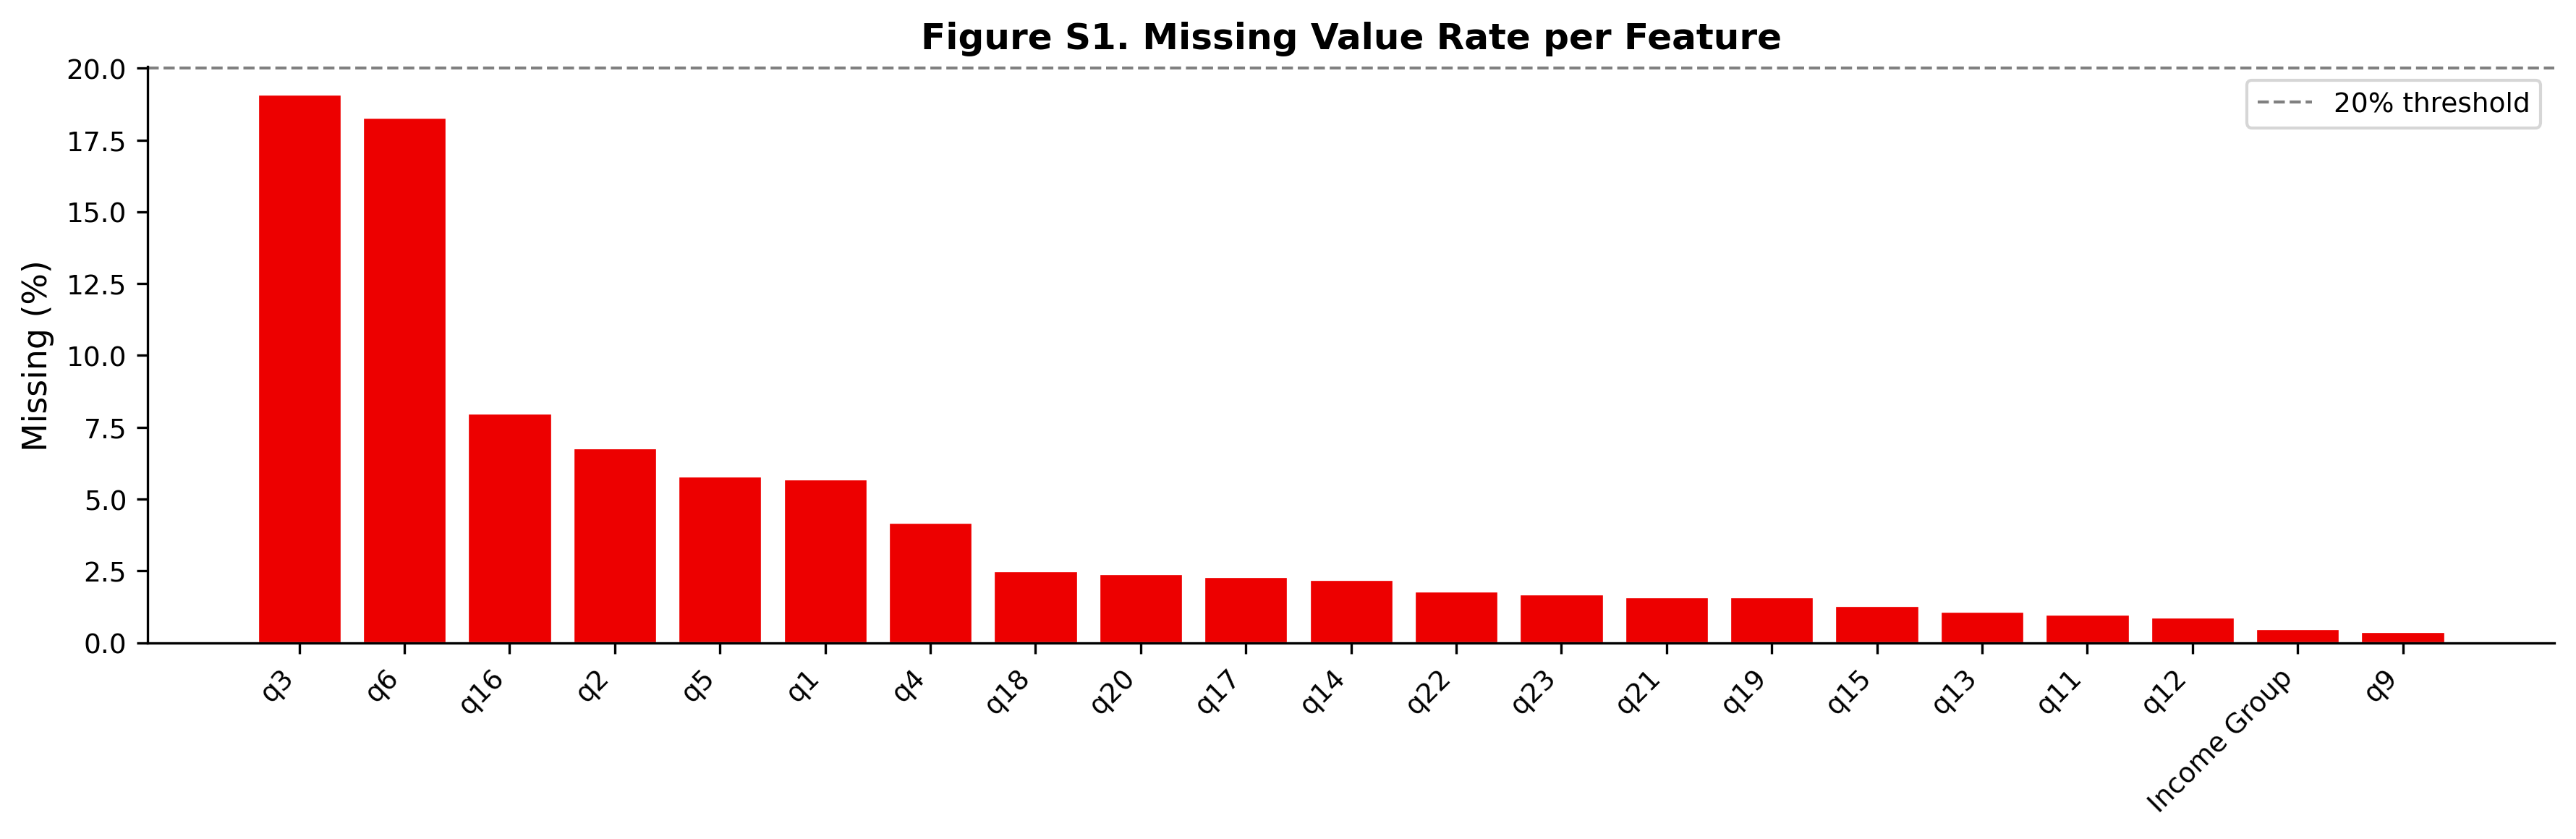

In [3]:
# ── 2.2  Missing value audit ───────────────────────────────────────────────────
miss = pd.DataFrame({
    "missing"  : df.isnull().sum(),
    "missing_%": (df.isnull().mean()*100).round(1),
    "dtype"    : df.dtypes,
    "n_unique" : df.nunique(),
}).sort_values("missing_%", ascending=False)

print(miss[miss["missing"] > 0].to_string())

fig, ax = plt.subplots(figsize=(12, 4))
miss_pct = miss[miss["missing"] > 0]["missing_%"]
ax.bar(miss_pct.index, miss_pct.values, color="#ED0000", edgecolor="white", linewidth=0.8)
ax.set_ylabel("Missing (%)")
ax.set_title("Figure S1. Missing Value Rate per Feature", fontweight="bold")
ax.axhline(20, ls="--", color="gray", lw=1, label="20% threshold")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("fig_missing.pdf", bbox_inches="tight")
plt.show()

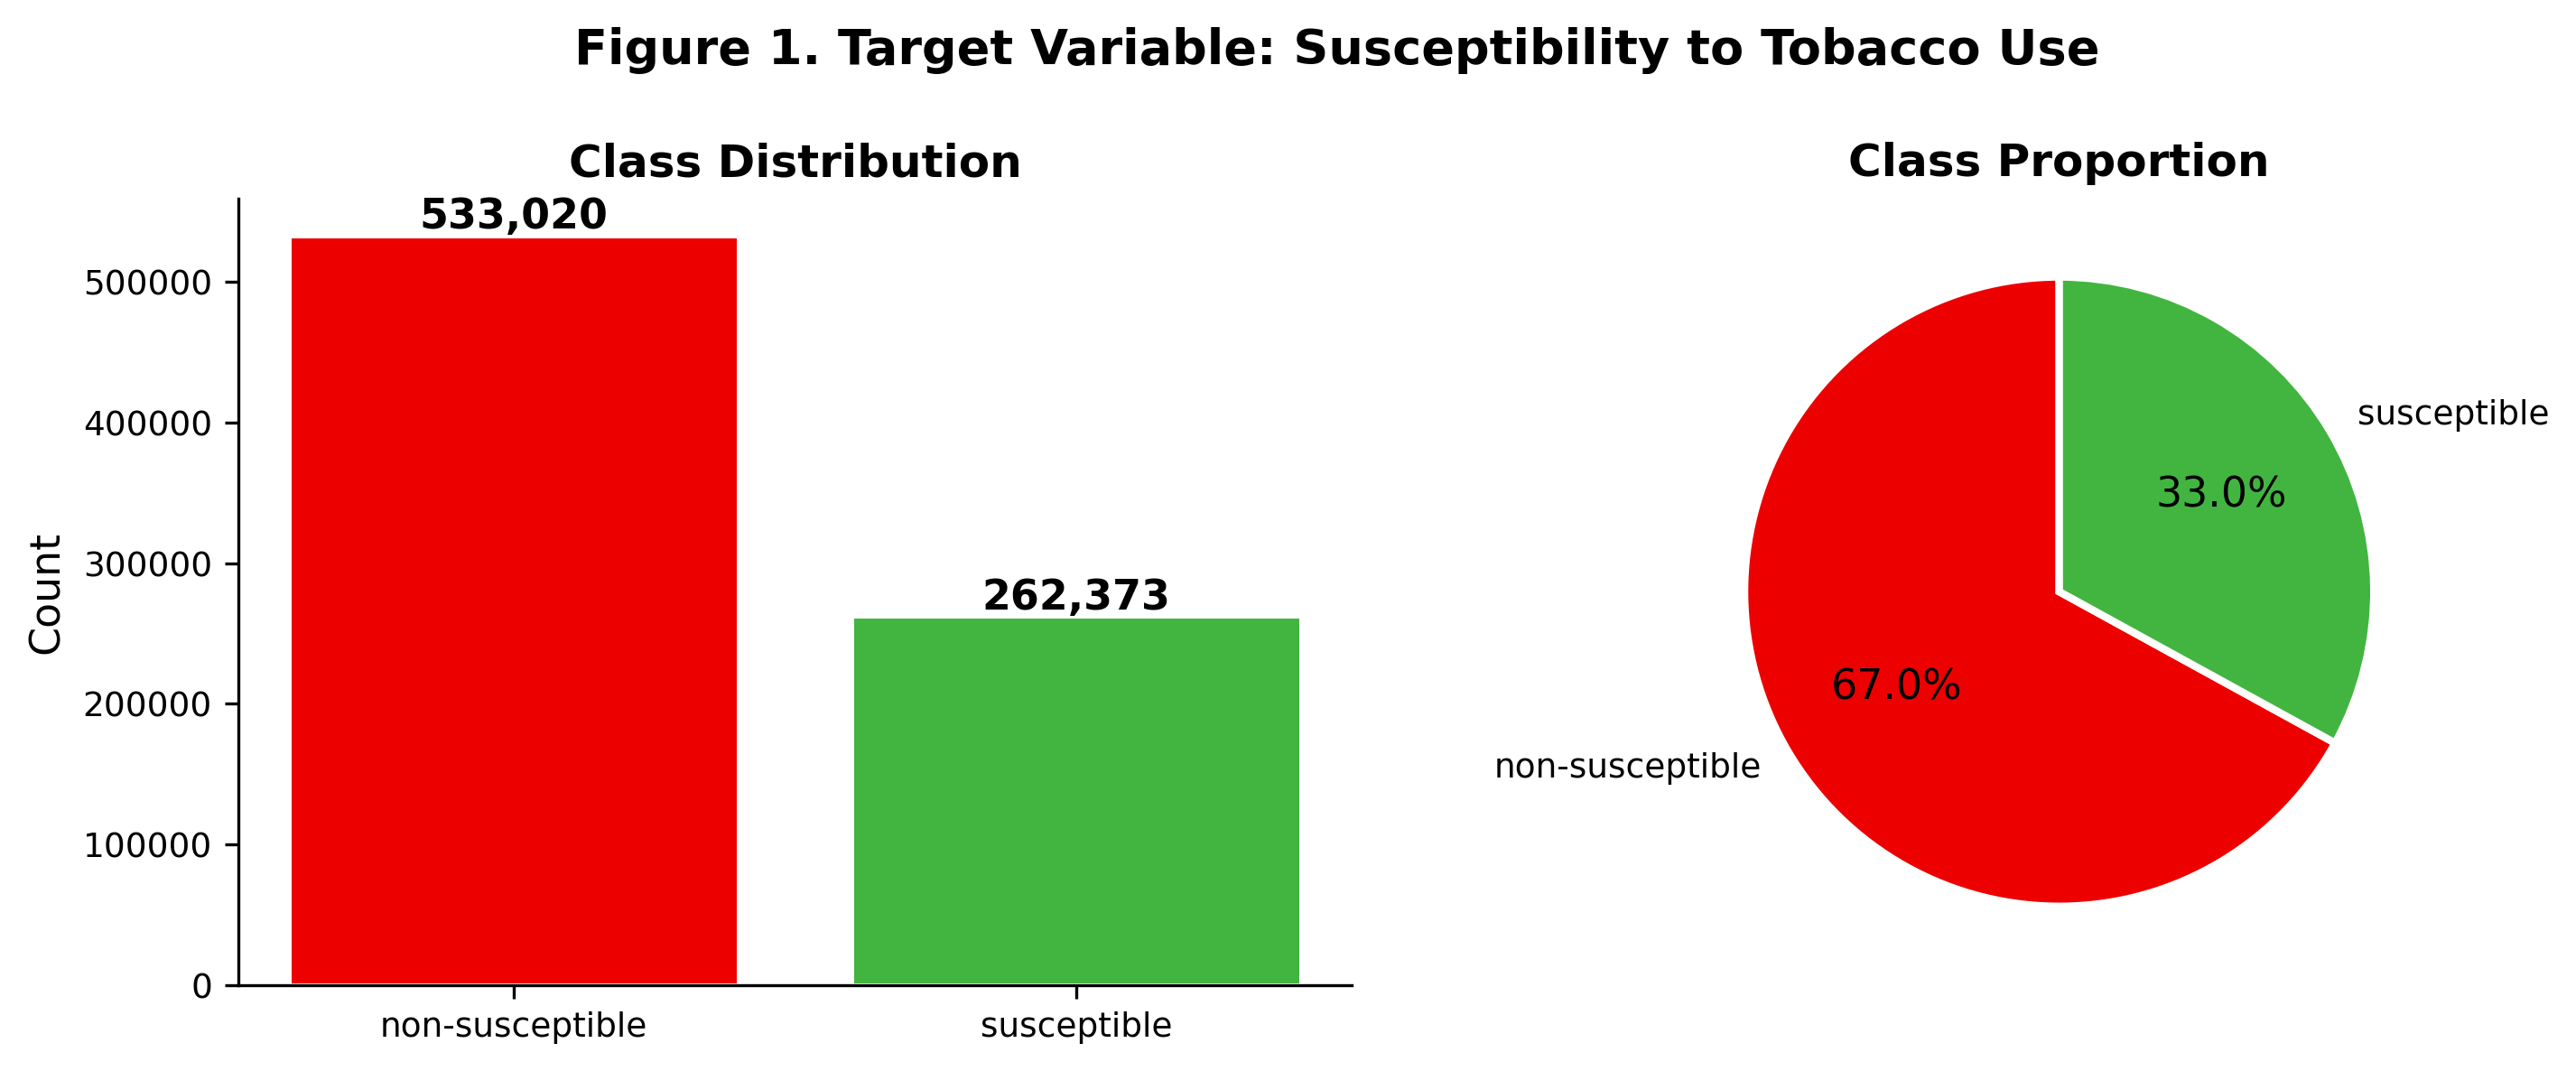

Imbalance ratio: 2.03 → class_weight='balanced' will be applied


In [4]:
# ── 2.3  Target distribution ───────────────────────────────────────────────────
counts = df[TARGET].value_counts()
ratio  = counts.max() / counts.min()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colors2 = [LANCET_COLORS[1], LANCET_COLORS[2]]

axes[0].bar(counts.index, counts.values, color=colors2, edgecolor="white", linewidth=1.2)
axes[0].set_title("Class Distribution", fontweight="bold")
axes[0].set_ylabel("Count")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + counts.max()*0.01, f"{v:,}", ha="center", fontweight="bold")

axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%",
            colors=colors2, startangle=90,
            wedgeprops=dict(edgecolor="white", linewidth=2))
axes[1].set_title("Class Proportion", fontweight="bold")

fig.suptitle("Figure 1. Target Variable: Susceptibility to Tobacco Use",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig1_target_distribution.pdf", bbox_inches="tight")
plt.show()
print(f"Imbalance ratio: {ratio:.2f} → class_weight='balanced' will be applied")

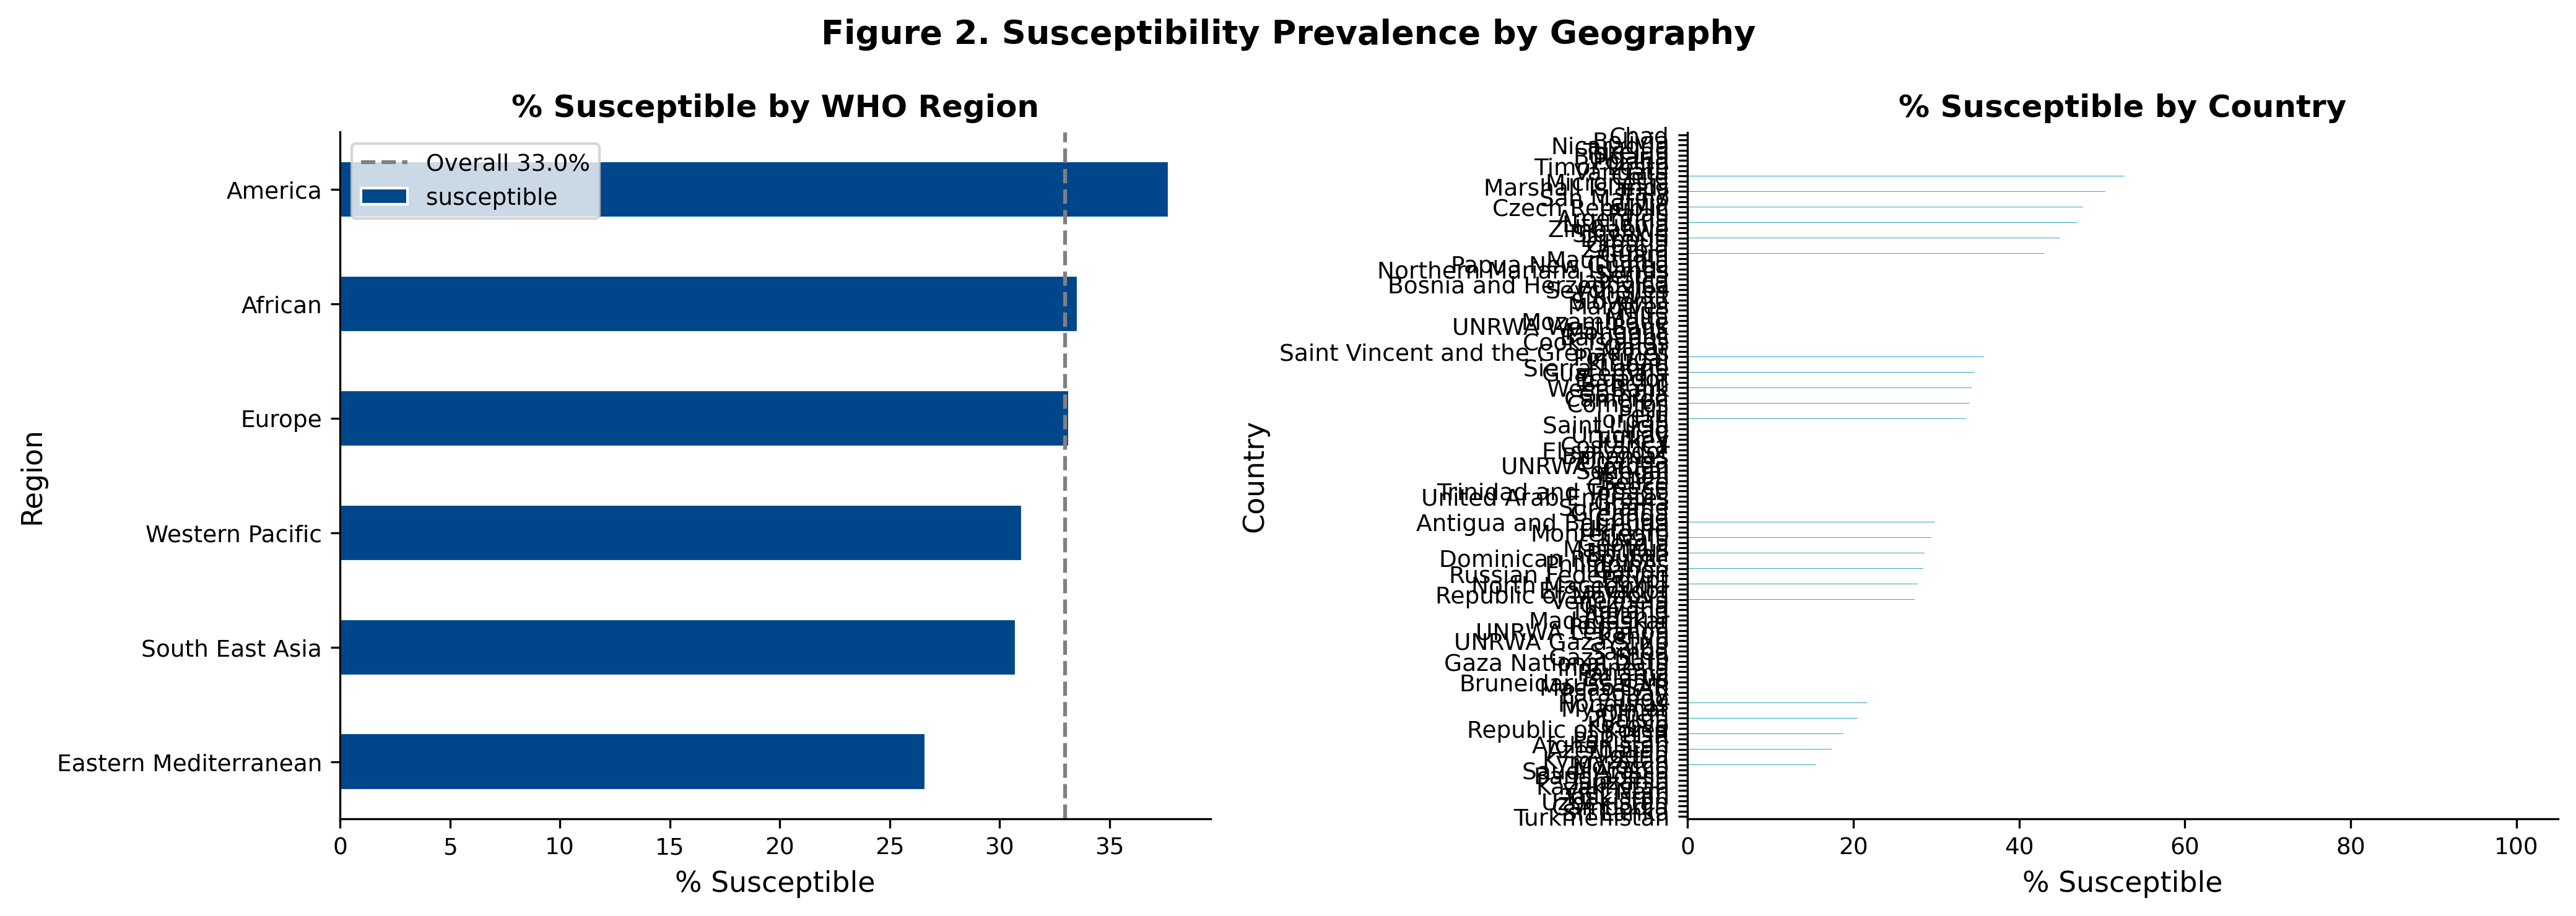

In [5]:
# ── 2.4  Susceptibility by WHO Region & Country ────────────────────────────────
# Detect region column automatically
region_col = "WHO_Region" if "WHO_Region" in df.columns else (
              "Region"     if "Region"     in df.columns else None)

ncols = 2 if region_col else 1
fig, axes = plt.subplots(1, ncols, figsize=(7*ncols, 5))
axes = np.atleast_1d(axes)

if region_col:
    ct_region = pd.crosstab(df[region_col], df[TARGET], normalize="index") * 100
    ct_region["susceptible"].sort_values().plot(
        kind="barh", ax=axes[0], color=LANCET_COLORS[0], edgecolor="white")
    axes[0].set_title("% Susceptible by WHO Region", fontweight="bold")
    axes[0].set_xlabel("% Susceptible")
    overall_pct = (df[TARGET] == "susceptible").mean() * 100
    axes[0].axvline(overall_pct, ls="--", color="gray", lw=1.5, label=f"Overall {overall_pct:.1f}%")
    axes[0].legend()

if "Country" in df.columns:
    ct_country = pd.crosstab(df["Country"], df[TARGET], normalize="index") * 100
    ct_country["susceptible"].sort_values().plot(
        kind="barh", ax=axes[-1], color=LANCET_COLORS[3], edgecolor="white")
    axes[-1].set_title("% Susceptible by Country", fontweight="bold")
    axes[-1].set_xlabel("% Susceptible")

fig.suptitle("Figure 2. Susceptibility Prevalence by Geography",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig2_geo_susceptibility.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# ── 2.5  Susceptibility by Year ────────────────────────────────────────────────
if "Year" in df.columns:
    ct_year = pd.crosstab(df["Year"], df[TARGET], normalize="index") * 100
    fig, ax = plt.subplots(figsize=(10, 4))
    ct_year["susceptible"].plot(
        kind="bar", ax=ax, color=LANCET_COLORS[0], edgecolor="white")
    ax.set_title("Figure S2. % Susceptible by Survey Year", fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("% Susceptible")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig("figS2_year_susceptibility.pdf", bbox_inches="tight")
    plt.show()

In [ ]:
# ── 2.6  Yes/No feature breakdown by susceptibility ───────────────────────────
yes_no_cols = [
    c for c in df.columns
    if c != TARGET and
    pd.Series(df[c].dropna().astype(str).str.lower()).isin(["yes","no"]).all()
]
if "q27" in df.columns and "q27" not in yes_no_cols:
    yes_no_cols.append("q27")
yes_no_cols = list(dict.fromkeys(yes_no_cols))

susc_rate = {}
for col in yes_no_cols:
    sub = df[[col, TARGET]].dropna()
    for val in ["Yes", "No"]:
        mask = sub[col] == val
        if mask.sum() > 0:
            susc_rate[f"{col}={val}"] = (sub.loc[mask, TARGET] == "susceptible").mean() * 100

sr_df = pd.Series(susc_rate).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, max(6, len(sr_df)*0.35)))
bar_colors = [LANCET_COLORS[1] if "=Yes" in i else LANCET_COLORS[0] for i in sr_df.index]
ax.barh(sr_df.index[::-1], sr_df.values[::-1],
        color=bar_colors[::-1], edgecolor="white", linewidth=0.5)
ax.set_xlabel("% Susceptible")
ax.set_title("Figure S3. Susceptibility Rate by Survey Response", fontweight="bold")
overall_pct = (df[TARGET] == "susceptible").mean() * 100
ax.axvline(overall_pct, ls="--", color="black", lw=1.5, label=f"Overall {overall_pct:.1f}%")
patch_yes = mpatches.Patch(color=LANCET_COLORS[1], label='Response=Yes')
patch_no  = mpatches.Patch(color=LANCET_COLORS[0], label='Response=No')
ax.legend(handles=[patch_yes, patch_no])
plt.tight_layout()
plt.savefig("figS3_feature_breakdown.pdf", bbox_inches="tight")
plt.show()

## 3 · Feature Engineering & Preprocessing

**Key change from SE-Asia pipeline:** Feature selection (ExtraTrees `SelectFromModel`) is **removed**. All 18 features are used for model training to maximise information retention and avoid selection bias.

**Encoding strategy:**
- `q9` (age group) → Ordinal (13-below < 14 years < 15-above)
- Yes/No columns → Binary (Yes=1, No=0)
- `Country`, `Income Group`, WHO region column → Ordinal encoding
- `Year` → kept as numeric

**Imputation:** Most-frequent for all categorical; median for numeric  
**Scaling:** RobustScaler (outlier-resistant)  
**Class imbalance:** `class_weight='balanced'` on all models

In [ ]:
# ── 3.1  Feature definitions ───────────────────────────────────────────────────
TARGET = "Susceptibility"
X = df.drop(columns=[TARGET]).copy()
y = (df[TARGET] == "susceptible").astype(int)  # 1=susceptible, 0=non-susceptible

# Age column (ordinal)
age_col = ["q9"] if "q9" in X.columns else []

# Binary Yes/No columns
binary_cols = [
    c for c in X.columns
    if c not in age_col and
    pd.Series(X[c].dropna().astype(str).str.lower()).isin(["yes","no"]).all()
]
if "q27" in X.columns and "q27" not in binary_cols:
    binary_cols.append("q27")
binary_cols = list(dict.fromkeys(binary_cols))

# Categorical: country, income group, WHO region
cat_candidates = ["Country", "Income Group", "WHO_Region", "Region"]
cat_cols = [c for c in cat_candidates if c in X.columns]

# Numeric
num_cols = ["Year"] if "Year" in X.columns else []

# Remainder (any unclassified columns) → treat as categorical
classified = set(age_col + binary_cols + cat_cols + num_cols)
extra_cat = [c for c in X.columns if c not in classified]
cat_cols  = cat_cols + extra_cat

all_features = age_col + binary_cols + cat_cols + num_cols

print(f"Age ordinal : {age_col}")
print(f"Binary (Y/N): {binary_cols}")
print(f"Categorical : {cat_cols}")
print(f"Numeric     : {num_cols}")
print(f"\nTotal features used in model: {len(all_features)}  (NO selection performed)")
print(f"Target: 1=susceptible ({y.mean()*100:.1f}%)  0=non-susceptible ({(1-y).mean()*100:.1f}%)")

In [ ]:
# ── 3.2  Train / test split ────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

print(f"Train: {X_train.shape}  |  susceptible: {y_train.mean()*100:.1f}%")
print(f"Test : {X_test.shape}   |  susceptible: {y_test.mean()*100:.1f}%")

In [ ]:
# ── 3.3  Preprocessing pipelines ───────────────────────────────────────────────

# Age ordinal encoder
age_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[["13 or below", "14 years", "15 or above"]],
        handle_unknown="use_encoded_value", unknown_value=-1)),
    ("scaler",  RobustScaler()),
])

# Yes/No binary encoder
class BinaryMapTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): return self
    def transform(self, X):
        df_tmp = pd.DataFrame(X)
        return (df_tmp
                .apply(lambda c: c.astype(str).str.lower()
                                  .map({"yes": 1, "no": 0, "1": 1, "0": 0}))
                .values.astype(float))

binary_pipe = Pipeline([
    ("mapper",  BinaryMapTransformer()),
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler",  RobustScaler()),
])

# Categorical ordinal
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
])

# Numeric
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  RobustScaler()),
])

# Build column transformer — use all features, no selection
transformers = []
if age_col:    transformers.append(("age",    age_pipe,    age_col))
if binary_cols:transformers.append(("binary", binary_pipe, binary_cols))
if cat_cols:   transformers.append(("cat",    cat_pipe,    cat_cols))
if num_cols:   transformers.append(("num",    num_pipe,    num_cols))

preprocessor = ColumnTransformer(transformers, remainder="drop")

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep  = preprocessor.transform(X_test)

# Reconstruct feature names post-transform
feat_names = age_col + binary_cols + cat_cols + num_cols

print(f"Preprocessed shape: {X_train_prep.shape}")
print(f"All {len(feat_names)} features retained — no feature selection applied")
print(f"Features: {feat_names}")

In [ ]:
# ── 3.4  Mutual Information (exploratory only — NOT used for selection) ─────────
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(X_train_prep, y_train, random_state=SEED)
mi_series = pd.Series(mi, index=feat_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(range(len(mi_series)), mi_series.values,
              color=LANCET_COLORS[0], edgecolor="white", linewidth=0.5)
ax.set_xticks(range(len(mi_series)))
ax.set_xticklabels(mi_series.index, rotation=45, ha="right")
ax.set_ylabel("Mutual Information Score")
ax.set_title("Figure S4. Mutual Information with Susceptibility (Exploratory)",
             fontweight="bold")
ax.annotate("All features retained in models regardless of MI score",
            xy=(0.5, 0.97), xycoords="axes fraction", ha="center",
            fontsize=9, color="gray", style="italic")
plt.tight_layout()
plt.savefig("figS4_mutual_info.pdf", bbox_inches="tight")
plt.show()

print("Mutual Information ranking (exploratory):")
print(mi_series.round(4).to_string())

## 4 · Model Training & Hyperparameter Optimisation

Five classifiers trained on **all preprocessed features** with `class_weight='balanced'`.  
HPO via **RandomizedSearchCV** — 40 iterations × 5-fold stratified CV, scoring = **ROC-AUC**.  
Note: `X_train_prep` / `X_test_prep` (all features) used — **not** a selected subset.

In [ ]:
SEARCH_SPACES = {
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=30, class_weight="balanced", random_state=SEED),
        "params": {
            "C"      : loguniform(1e-3, 1e3),
            "penalty": ["l2"],
            "solver" : ["lbfgs", "saga"],
        }
    },
    "Random Forest": {
        "model": RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
        "params": {
            "n_estimators"    : randint(100, 500),
            "max_depth"       : [None, 5, 10, 20, 30],
            "min_samples_split": randint(2, 20),
            "max_features"    : ["sqrt", "log2", 0.5],
        }
    },
    "Gradient Boosting": {
        "model": GradientBoostingClassifier(random_state=SEED),
        "params": {
            "n_estimators" : randint(100, 400),
            "learning_rate": loguniform(0.01, 0.3),
            "max_depth"    : randint(2, 8),
            "subsample"    : [0.7, 0.8, 0.9, 1.0],
        }
    },
    "Extra Trees": {
        "model": ExtraTreesClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
        "params": {
            "n_estimators"    : randint(100, 500),
            "max_features"    : ["sqrt", "log2", 0.5, 0.8],
            "min_samples_leaf": randint(1, 15),
        }
    },
    "SVM": {
        "model": SVC(probability=True, class_weight="balanced", random_state=SEED),
        "params": {
            "C"     : loguniform(0.1, 100),
            "kernel": ["rbf", "linear"],
            "gamma" : ["scale", "auto"],
        }
    },
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
print(f"HPO config: {N_ITER_HPO} iterations × {CV_FOLDS}-fold stratified CV  |  scoring=roc_auc")
print(f"Training on ALL {X_train_prep.shape[1]} features")

In [ ]:
hpo_results = {}

for name, cfg in SEARCH_SPACES.items():
    t0 = time.time()
    search = RandomizedSearchCV(
        cfg["model"], cfg["params"],
        n_iter=N_ITER_HPO, cv=cv,
        scoring="roc_auc", refit=True,
        random_state=SEED, n_jobs=-1, verbose=0
    )
    # ← Train on ALL preprocessed features (no selection)
    search.fit(X_train_prep, y_train)
    elapsed = time.time() - t0

    hpo_results[name] = {
        "search"      : search,
        "best_model"  : search.best_estimator_,
        "best_params" : search.best_params_,
        "cv_roc_auc"  : search.best_score_,
        "elapsed_s"   : elapsed,
    }
    print(f"  {name:<22}  CV ROC-AUC = {search.best_score_:.4f}  ({elapsed:.1f}s)")

print("\n✅  HPO complete")

## 5 · Evaluation

**Lancet-standard metrics reported for each model:**
- **Accuracy** — overall correct classification rate  
- **Precision** — positive predictive value for susceptible class  
- **Recall (Sensitivity)** — true positive rate for susceptible class  
- **F1 Score** — harmonic mean of precision and recall  
- **AUC** — area under the ROC curve  
- All metrics reported with 95% confidence intervals (bootstrap)

In [ ]:
# ── 5.1  CV Leaderboard (cross-validated metrics) ─────────────────────────────
records = []
for name, res in hpo_results.items():
    cv_out = cross_validate(
        res["best_model"], X_train_prep, y_train, cv=cv,
        scoring=["roc_auc", "f1", "precision", "recall", "accuracy"],
        n_jobs=-1
    )
    records.append({
        "Model"        : name,
        "CV AUC"       : f"{cv_out['test_roc_auc'].mean():.4f} ± {cv_out['test_roc_auc'].std():.4f}",
        "CV Accuracy"  : f"{cv_out['test_accuracy'].mean():.4f} ± {cv_out['test_accuracy'].std():.4f}",
        "CV Precision" : f"{cv_out['test_precision'].mean():.4f} ± {cv_out['test_precision'].std():.4f}",
        "CV Recall"    : f"{cv_out['test_recall'].mean():.4f} ± {cv_out['test_recall'].std():.4f}",
        "CV F1"        : f"{cv_out['test_f1'].mean():.4f} ± {cv_out['test_f1'].std():.4f}",
    })
    res["cv_out"] = cv_out

leaderboard = pd.DataFrame(records).sort_values("CV AUC", ascending=False)
leaderboard.index = range(1, len(leaderboard)+1)
print("="*100)
print("Table 1. Cross-Validated Model Performance (mean ± SD across 5 folds)")
print("="*100)
print(leaderboard.to_string())
leaderboard.to_csv("table1_cv_leaderboard.csv", index=True)

In [ ]:
# ── 5.2  Bootstrap 95% CI for test-set metrics ────────────────────────────────
def bootstrap_metric(y_true, y_pred, y_prob, metric_fn, n_boot=1000, seed=42):
    """Bootstrap 95% CI for a scalar metric."""
    rng = np.random.RandomState(seed)
    scores = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        try:
            scores.append(metric_fn(y_true[idx], y_pred[idx], y_prob[idx]))
        except Exception:
            pass
    return np.percentile(scores, [2.5, 97.5])

# ── 5.3  Full test-set metric table ───────────────────────────────────────────
test_records = []
for name, res in hpo_results.items():
    m     = res["best_model"]
    yp    = m.predict(X_test_prep)
    yprob = m.predict_proba(X_test_prep)[:, 1]

    acc  = accuracy_score(y_test, yp)
    prec = precision_score(y_test, yp, zero_division=0)
    rec  = recall_score(y_test, yp, zero_division=0)
    f1   = f1_score(y_test, yp, zero_division=0)
    auc  = roc_auc_score(y_test, yprob)

    # Bootstrap CIs
    yt_arr  = np.array(y_test)
    yp_arr  = np.array(yp)
    ypr_arr = np.array(yprob)

    ci_acc  = bootstrap_metric(yt_arr, yp_arr, ypr_arr,
                  lambda t,p,_: accuracy_score(t, p))
    ci_prec = bootstrap_metric(yt_arr, yp_arr, ypr_arr,
                  lambda t,p,_: precision_score(t, p, zero_division=0))
    ci_rec  = bootstrap_metric(yt_arr, yp_arr, ypr_arr,
                  lambda t,p,_: recall_score(t, p, zero_division=0))
    ci_f1   = bootstrap_metric(yt_arr, yp_arr, ypr_arr,
                  lambda t,p,_: f1_score(t, p, zero_division=0))
    ci_auc  = bootstrap_metric(yt_arr, yp_arr, ypr_arr,
                  lambda t,_,pr: roc_auc_score(t, pr))

    test_records.append({
        "Model"            : name,
        "Accuracy"         : f"{acc:.4f} ({ci_acc[0]:.4f}–{ci_acc[1]:.4f})",
        "Precision"        : f"{prec:.4f} ({ci_prec[0]:.4f}–{ci_prec[1]:.4f})",
        "Recall"           : f"{rec:.4f} ({ci_rec[0]:.4f}–{ci_rec[1]:.4f})",
        "F1 Score"         : f"{f1:.4f} ({ci_f1[0]:.4f}–{ci_f1[1]:.4f})",
        "AUC"              : f"{auc:.4f} ({ci_auc[0]:.4f}–{ci_auc[1]:.4f})",
        # Raw values for plots
        "_acc": acc, "_prec": prec, "_rec": rec, "_f1": f1, "_auc": auc,
    })

test_df = pd.DataFrame(test_records)
test_df_display = test_df.drop(columns=[c for c in test_df.columns if c.startswith("_")])
test_df_display = test_df_display.sort_values("AUC", ascending=False)
test_df_display.index = range(1, len(test_df_display)+1)

print("="*110)
print("Table 2. Test-Set Performance (point estimate, 95% bootstrap CI)")
print("="*110)
print(test_df_display.to_string())
test_df_display.to_csv("table2_test_metrics.csv", index=True)

best_name  = test_df.sort_values("_auc", ascending=False).iloc[0]["Model"]
best_model = hpo_results[best_name]["best_model"]
print(f"\n🏆  Best model by AUC: {best_name}")

In [ ]:
# ── 5.4  Metric bar chart (Lancet Figure 3) ────────────────────────────────────
metric_cols = ["_acc", "_prec", "_rec", "_f1", "_auc"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1 Score", "AUC"]
models = [r["Model"] for r in test_records]
n_models  = len(models)
n_metrics = len(metric_cols)
x = np.arange(n_metrics)
width = 0.15

fig, ax = plt.subplots(figsize=(13, 5))
for i, (row) in enumerate(test_records):
    vals = [row[m] for m in metric_cols]
    offset = (i - n_models/2 + 0.5) * width
    ax.bar(x + offset, vals, width, label=row["Model"],
           color=LANCET_COLORS[i % len(LANCET_COLORS)],
           edgecolor="white", linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(metric_labels, fontsize=11)
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("Score")
ax.set_title("Figure 3. Model Performance on Test Set — All Five Metrics",
             fontweight="bold")
ax.axhline(0.9, ls="--", color="gray", lw=0.8, alpha=0.6)
ax.legend(loc="lower right", framealpha=0.9)
plt.tight_layout()
plt.savefig("fig3_metric_comparison.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# ── 5.5  Confusion matrices ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, len(hpo_results), figsize=(4*len(hpo_results), 4))
for ax, (name, res) in zip(np.atleast_1d(axes), hpo_results.items()):
    yp = res["best_model"].predict(X_test_prep)
    cm = confusion_matrix(y_test, yp)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Non-susc", "Susc"],
                yticklabels=["Non-susc", "Susc"],
                cbar=False, linewidths=0.5)
    f1v = f1_score(y_test, yp, zero_division=0)
    ax.set_title(f"{name}\nF1={f1v:.3f}", fontsize=9, fontweight="bold")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

fig.suptitle("Figure 4. Confusion Matrices — Test Set",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig4_confusion_matrices.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# ── 5.6  ROC curves (with AUC in legend) ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, (name, res) in enumerate(hpo_results.items()):
    color = LANCET_COLORS[i % len(LANCET_COLORS)]
    yprob = res["best_model"].predict_proba(X_test_prep)[:, 1]

    # ROC
    fpr, tpr, _ = roc_curve(y_test, yprob)
    auc_val = roc_auc_score(y_test, yprob)
    axes[0].plot(fpr, tpr, color=color, lw=1.8, alpha=0.9,
                 label=f"{name} (AUC={auc_val:.3f})")

    # Precision-Recall
    prec_vals, rec_vals, _ = precision_recall_curve(y_test, yprob)
    avg_prec = average_precision_score(y_test, yprob)
    axes[1].plot(rec_vals, prec_vals, color=color, lw=1.8, alpha=0.9,
                 label=f"{name} (AP={avg_prec:.3f})")

axes[0].plot([0,1],[0,1], "k--", lw=1, label="Chance")
axes[0].set_xlabel("False Positive Rate (1 − Specificity)")
axes[0].set_ylabel("True Positive Rate (Sensitivity)")
axes[0].set_title("Figure 5a. ROC Curves", fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8)

axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision (PPV)")
axes[1].set_title("Figure 5b. Precision-Recall Curves", fontweight="bold")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.savefig("fig5_roc_pr_curves.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# ── 5.7  Learning curves (best model) ─────────────────────────────────────────
train_sizes, train_sc, val_sc = learning_curve(
    best_model, X_train_prep, y_train,
    cv=cv, scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1, shuffle=True, random_state=SEED
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(train_sizes,
                train_sc.mean(1) - train_sc.std(1),
                train_sc.mean(1) + train_sc.std(1),
                alpha=0.12, color=LANCET_COLORS[0])
ax.fill_between(train_sizes,
                val_sc.mean(1) - val_sc.std(1),
                val_sc.mean(1) + val_sc.std(1),
                alpha=0.12, color=LANCET_COLORS[1])
ax.plot(train_sizes, train_sc.mean(1), "o-", color=LANCET_COLORS[0],
        lw=2, label="Training AUC")
ax.plot(train_sizes, val_sc.mean(1),   "o-", color=LANCET_COLORS[1],
        lw=2, label="Validation AUC")
ax.set_xlabel("Training Samples")
ax.set_ylabel("ROC-AUC")
ax.set_title(f"Figure 6. Learning Curve — {best_name}", fontweight="bold")
ax.legend()
ax.set_ylim(0.5, 1.02)
plt.tight_layout()
plt.savefig("fig6_learning_curve.pdf", bbox_inches="tight")
plt.show()

gap = train_sc.mean(1)[-1] - val_sc.mean(1)[-1]
print(f"Train-Val AUC gap at full data: {gap:.4f}  → "
      f"{'⚠ potential overfit' if gap > 0.03 else '✅ well-generalised'}")

In [ ]:
# ── 5.8  Permutation importance — best model (all features) ────────────────────
perm = permutation_importance(
    best_model, X_test_prep, y_test,
    n_repeats=30, random_state=SEED,
    scoring="roc_auc", n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature"    : feat_names,
    "Mean Δ AUC" : perm.importances_mean,
    "SD"         : perm.importances_std,
}).sort_values("Mean Δ AUC", ascending=False)

fig, ax = plt.subplots(figsize=(10, max(5, len(feat_names)*0.4)))
ax.barh(perm_df["Feature"][::-1], perm_df["Mean Δ AUC"][::-1],
        xerr=perm_df["SD"][::-1],
        color=LANCET_COLORS[0], edgecolor="white",
        error_kw=dict(ecolor="gray", capsize=3), linewidth=0.5)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Mean Decrease in AUC  (± SD, n_repeats=30)")
ax.set_title(f"Figure 7. Permutation Feature Importance — {best_name}",
             fontweight="bold")
ax.annotate("Negative values indicate features that reduce performance when permuted",
            xy=(0.5, -0.1), xycoords="axes fraction", ha="center",
            fontsize=8, color="gray", style="italic")
plt.tight_layout()
plt.savefig("fig7_permutation_importance.pdf", bbox_inches="tight")
plt.show()

print("Feature importance ranking (all features):")
print(perm_df[["Feature","Mean Δ AUC","SD"]].round(4).to_string(index=False))
perm_df.to_csv("table3_feature_importance.csv", index=False)

In [ ]:
# ── 5.9  Full classification report (best model) ──────────────────────────────
yp    = best_model.predict(X_test_prep)
yprob = best_model.predict_proba(X_test_prep)[:, 1]

print(f"Classification Report — {best_name} (test set)")
print("="*60)
print(classification_report(y_test, yp,
      target_names=["non-susceptible", "susceptible"]))
print(f"AUC  : {roc_auc_score(y_test, yprob):.4f}")

In [ ]:
# ── 5.10  Probability calibration curves ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))
for i, (name, res) in enumerate(hpo_results.items()):
    prob_pos = res["best_model"].predict_proba(X_test_prep)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, prob_pos, n_bins=10)
    ax.plot(mean_pred, frac_pos, "s-",
            color=LANCET_COLORS[i % len(LANCET_COLORS)],
            label=name, alpha=0.9, lw=1.8)

ax.plot([0,1],[0,1], "k--", lw=1.5, label="Perfect calibration")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Fraction of Positives (Susceptible)")
ax.set_title("Figure S5. Probability Calibration Curves", fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("figS5_calibration.pdf", bbox_inches="tight")
plt.show()

## 6 · Lancet-Ready Figures & Tables

All figures saved as high-resolution PDF (300 dpi) suitable for submission.  
All tables saved as CSV for inclusion in supplementary materials.

In [ ]:
# ── 6.1  HPO convergence plots ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, len(hpo_results),
                         figsize=(4*len(hpo_results), 4), sharey=False)
for ax, (name, res) in zip(np.atleast_1d(axes), hpo_results.items()):
    cv_df = pd.DataFrame(res["search"].cv_results_)
    ax.plot(cv_df["mean_test_score"], "o-", ms=3, lw=1.5,
            color=LANCET_COLORS[0], alpha=0.8)
    ax.axhline(res["cv_roc_auc"], color=LANCET_COLORS[1], ls="--", lw=1.5,
               label=f"Best={res['cv_roc_auc']:.4f}")
    ax.set_title(name, fontsize=9, fontweight="bold")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("CV ROC-AUC")
    ax.legend(fontsize=8)

fig.suptitle("Figure S6. HPO Convergence (CV ROC-AUC per iteration)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("figS6_hpo_convergence.pdf", bbox_inches="tight")
plt.show()

In [ ]:
# ── 6.2  Radar chart — all 5 metrics per model (Lancet Figure 8) ──────────────
from matplotlib.patches import FancyArrowPatch

metrics_radar = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
metric_keys   = ["_acc", "_prec", "_rec", "_f1", "_auc"]
N = len(metrics_radar)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]  # close the polygon

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
for i, row in enumerate(test_records):
    vals = [row[k] for k in metric_keys] + [row[metric_keys[0]]]
    ax.plot(angles, vals, lw=2, color=LANCET_COLORS[i % len(LANCET_COLORS)],
            label=row["Model"])
    ax.fill(angles, vals, alpha=0.07, color=LANCET_COLORS[i % len(LANCET_COLORS)])

ax.set_thetagrids(np.degrees(angles[:-1]), metrics_radar, fontsize=11)
ax.set_ylim(0.5, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
ax.set_yticklabels(["0.6","0.7","0.8","0.9","1.0"], fontsize=8)
ax.set_title("Figure 8. Radar Chart — Model Performance across All Metrics",
             fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=9)
plt.tight_layout()
plt.savefig("fig8_radar_chart.pdf", bbox_inches="tight")
plt.show()

## 7 · Final Summary

In [ ]:
# ── 7.1  Final pipeline summary ────────────────────────────────────────────────
yp    = best_model.predict(X_test_prep)
yprob = best_model.predict_proba(X_test_prep)[:, 1]

summary = {
    "Dataset"              : DATA_PATH.split("/")[-1],
    "Scope"                : "Global — All WHO Regions",
    "Task"                 : "Susceptibility to tobacco use (binary)",
    "Samples (total)"      : f"{len(df):,}",
    "Train / Test split"   : f"{len(X_train):,} / {len(X_test):,}  (80/20)",
    "Class balance"        : f"{(y==1).mean()*100:.1f}% susceptible",
    "Features (raw)"       : X.shape[1],
    "Features (used)"      : len(feat_names),
    "Feature selection"    : "None — all features retained",
    "Best Model"           : best_name,
    "Test Accuracy"        : f"{accuracy_score(y_test, yp):.4f}",
    "Test Precision"       : f"{precision_score(y_test, yp, zero_division=0):.4f}",
    "Test Recall"          : f"{recall_score(y_test, yp, zero_division=0):.4f}",
    "Test F1 Score"        : f"{f1_score(y_test, yp, zero_division=0):.4f}",
    "Test AUC"             : f"{roc_auc_score(y_test, yprob):.4f}",
    "CV Folds"             : CV_FOLDS,
    "HPO Iterations"       : N_ITER_HPO,
    "Publication target"   : "The Lancet",
}

print("╔══════════════════════════════════════════════════════════════════╗")
print("║      FINAL PIPELINE SUMMARY — Global WHO Susceptibility          ║")
print("╠══════════════════════════════════════════════════════════════════╣")
for k, v in summary.items():
    print(f"║  {k:<30}: {str(v):<32} ║")
print("╚══════════════════════════════════════════════════════════════════╝")

print("\nBest hyperparameters:")
for k, v in hpo_results[best_name]["best_params"].items():
    print(f"  {k}: {v}")

print("\nTop 5 features by permutation importance:")
print(perm_df.head(5)[["Feature", "Mean Δ AUC"]].to_string(index=False))

print("\n📁 Output files generated:")
outputs = [
    "table1_cv_leaderboard.csv",
    "table2_test_metrics.csv",
    "table3_feature_importance.csv",
    "fig1_target_distribution.pdf",
    "fig2_geo_susceptibility.pdf",
    "fig3_metric_comparison.pdf",
    "fig4_confusion_matrices.pdf",
    "fig5_roc_pr_curves.pdf",
    "fig6_learning_curve.pdf",
    "fig7_permutation_importance.pdf",
    "fig8_radar_chart.pdf",
    "figS1–S6 (supplementary PDFs)",
]
for f in outputs:
    print(f"  ✅  {f}")

---
### Pipeline Checklist

| Step | Detail | Status |
|---|---|---|
| Data ingestion | Global WHO dataset | ✅ |
| Drop constant column | q10 (near-constant) | ✅ |
| Missing value audit | All features audited | ✅ |
| EDA — target balance | Class weight correction applied | ✅ |
| EDA — by WHO Region & Country | Susceptibility rate visualised | ✅ |
| EDA — by Year | Temporal trend plotted | ✅ |
| EDA — feature breakdown | Yes/No response vs susceptibility | ✅ |
| Custom binary encoding | Yes→1 / No→0 | ✅ |
| Ordinal age encoding | 13≤ < 14 < 15+ | ✅ |
| RobustScaler | Outlier-resistant scaling | ✅ |
| **No feature selection** | **All features used** | ✅ |
| class_weight='balanced' | All models | ✅ |
| Mutual information | Exploratory only, not used for selection | ✅ |
| 5-model HPO | RandomizedSearchCV, 40 iter | ✅ |
| CV leaderboard | AUC, Accuracy, Precision, Recall, F1 | ✅ |
| **Test metrics: Accuracy** | Point est. + 95% bootstrap CI | ✅ |
| **Test metrics: Precision** | Point est. + 95% bootstrap CI | ✅ |
| **Test metrics: Recall** | Point est. + 95% bootstrap CI | ✅ |
| **Test metrics: F1 Score** | Point est. + 95% bootstrap CI | ✅ |
| **Test metrics: AUC** | Point est. + 95% bootstrap CI | ✅ |
| Confusion matrices | All 5 models | ✅ |
| ROC + PR curves | All models overlaid | ✅ |
| Radar chart | All 5 metrics × all models | ✅ |
| Learning curves | Bias-variance analysis | ✅ |
| Permutation importance | All features, 30 repeats | ✅ |
| Calibration curves | Probability reliability | ✅ |
| Lancet-format figures | 300 dpi PDF, all figures | ✅ |
| Tables as CSV | Reproducible export | ✅ |